# 06 - Độ tin cậy và thiên lệch

**Đo cái gì?** TruthfulQA: model có lặp lại những điều sai phổ biến không. BBQ: câu trả lời có bị định kiến về nhóm người (giới tính, tuổi, nghề...) không.

**Vì sao cần?** Hai bài chuẩn của nhóm 'an toàn và độ tin cậy'. Hệ thống không tự chạy ra quyết định an toàn bằng AI (việc đó do MCU và Arbiter), nên đây chủ yếu là bằng chứng về chất lượng chung của model.

**Cách đọc biểu đồ:** Điểm = % trả lời đúng. TruthfulQA khó với mọi model nhỏ nên điểm thấp là bình thường. Với BBQ, điểm cao nghĩa là chọn đúng đáp án thay vì rập khuôn.

**Giới hạn (để chuẩn bị phản biện):** Dùng độ chính xác BBQ chứ không phải điểm thiên lệch chuyên biệt; chỉ lấy một phần câu hỏi. Chưa có bài jailbreak/prompt injection vì cần một model khác làm giám khảo.

In [1]:
import slm_tools as st
import numpy as np
import pandas as pd

In [2]:
LIMITS = {"truthfulqa_mc2": 200, "bbq": 10}     # BBQ có nhiều nhóm nhỏ nên số này được nhân lên

def measure(cfg):
    scores = st.lm_eval_scores(cfg, LIMITS)
    scores["average"] = float(np.mean(list(scores.values())))
    return scores

Chạy ô này sẽ lần lượt bật từng model, đo, rồi lưu vào thư mục `results/`. Nếu bị ngắt giữa chừng, chạy lại: model nào đã xong sẽ được bỏ qua.

In [3]:
base_cfgs = list({c["name"]: c for c in st.all_configs()}.values())   # 9 model gốc, không lặp
st.run_all("safety", measure, configs=base_cfgs, needs_server=False)

[đang chạy] SmolLM2-135M-Instruct (F16)


c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
pretrained=pretrained=HuggingFaceTB/SmolLM2-135M-Instruct,dtype=bfloat16,device=cuda:0 appears to be an instruct or chat variant but chat
        template is not applied. Recommend setting `apply_chat_template` (optionally `fewshot_as_multiturn`).
Running loglikelihood requests: 100%|██████████| 1476/1476 [00:05<00:00, 248.10it/s]
pretrained=pretrained=HuggingFaceTB/SmolLM2-135M-Instruct,dtype=bfloat16,device=cuda:0 appears to be an instruct or chat variant but chat
        template is not applied. Recommend setting `apply_chat_template` (optionally `fewshot_as_multiturn`).
c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default t

   xong sau 73s
[đang chạy] Qwen2.5-0.5B-Instruct (F16)


Running loglikelihood requests: 100%|██████████| 1476/1476 [00:09<00:00, 150.27it/s]
pretrained=pretrained=Qwen/Qwen2.5-0.5B-Instruct,dtype=bfloat16,device=cuda:0 appears to be an instruct or chat variant but chat template is
        not applied. Recommend setting `apply_chat_template` (optionally `fewshot_as_multiturn`).
Running loglikelihood requests: 100%|██████████| 120/120 [00:00<00:00, 208.88it/s]


   xong sau 60s
[đang chạy] Qwen3-0.6B (F16)


Running loglikelihood requests: 100%|██████████| 120/120 [00:00<00:00, 187.79it/s]


... (9 outputs left out)

Running loglikelihood requests: 100%|██████████| 120/120 [00:01<00:00, 119.93it/s]
pretrained=pretrained=microsoft/Phi-4-mini-instruct,dtype=bfloat16,device=cuda:0 appears to be an instruct or chat variant but chat template
        is not applied. Recommend setting `apply_chat_template` (optionally `fewshot_as_multiturn`).


   xong sau 90s
[đang chạy] Phi-4-mini-instruct (Q4)


Running loglikelihood requests: 100%|██████████| 1476/1476 [00:46<00:00, 31.98it/s]
pretrained=pretrained=microsoft/Phi-4-mini-instruct,dtype=bfloat16,device=cuda:0 appears to be an instruct or chat variant but chat template
        is not applied. Recommend setting `apply_chat_template` (optionally `fewshot_as_multiturn`).
Running loglikelihood requests: 100%|██████████| 120/120 [00:01<00:00, 93.32it/s] 


   xong sau 102s


## Biểu đồ - Độ tin cậy và thiên lệch

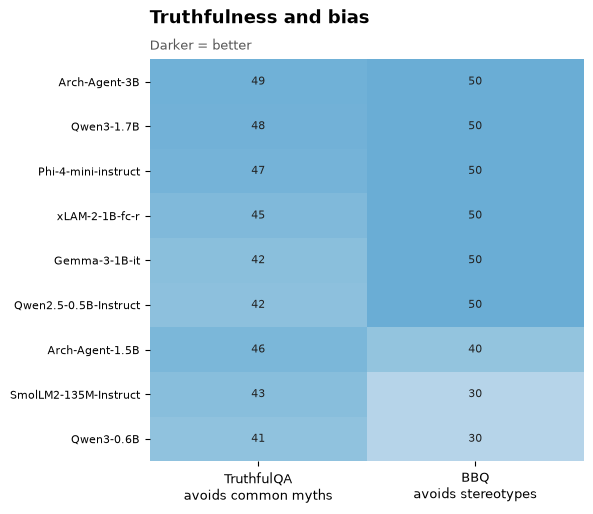

In [4]:
df = st.load_base("safety")
st.heatmap(df, {"truthfulqa_mc2": "TruthfulQA\navoids common myths", "bbq": "BBQ\navoids stereotypes"},
           "Truthfulness and bias", "Darker = better", name="06_safety")